In [1]:
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.datasets import EllipticBitcoinDataset
from torch_geometric.nn import GCNConv
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import fbeta_score, average_precision_score
import matplotlib.pyplot as plt

C:\Users\Manya Chaubey\elliptic_aml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Manya Chaubey\elliptic_aml\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
dataset = EllipticBitcoinDataset(root='../data/Elliptic')
data = dataset[0]

In [3]:
train_idx = data.train_mask.nonzero(as_tuple=True)[0].numpy()
test_idx = data.test_mask.nonzero(as_tuple=True)[0].numpy()

X = data.x.numpy()
y = data.y.numpy()

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

In [4]:
class GCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.5, training=self.training)
        return self.conv2(x, edge_index)

def train_gcn_subsampled(data, train_mask_sub, epochs=150):
    model = GCN(data.num_node_features, 64, 2)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    criterion = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, 10.0]))

    model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = criterion(out[train_mask_sub], data.y[train_mask_sub])
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        preds = out.argmax(dim=1)
        f2 = fbeta_score(data.y[data.test_mask].cpu(), preds[data.test_mask].cpu(), beta=2)
    return f2

In [9]:
# Label fractions to evaluate
fractions = [0.01, 0.05, 0.10, 1.00]
results = {"Random Forest": [], "XGBoost": [], "GCN": []}

np.random.seed(42)

for frac in fractions:
    print(f"\n--- Testing Label Fraction: {frac*100:.0f}% ---")
    
    # Generate subsampled mask for tabular models
    n_train = len(y_train)
    sub_indices = np.random.choice(n_train, size=int(n_train * frac), replace=False)
    
    X_tr_sub, y_tr_sub = X_train[sub_indices], y_train[sub_indices]

    # 1. Random Forest
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    rf.fit(X_tr_sub, y_tr_sub)
    rf_f2 = fbeta_score(y_test, rf.predict(X_test), beta=2)
    results["Random Forest"].append(rf_f2)
    print(f"Random Forest F2: {rf_f2:.4f}")


    # 2. XGBoost
    xgb = XGBClassifier(n_estimators=100, scale_pos_weight=10, random_state=42, n_jobs=-1)
    xgb.fit(X_tr_sub, y_tr_sub)
    xgb_f2 = fbeta_score(y_test, xgb.predict(X_test), beta=2)
    results["XGBoost"].append(xgb_f2)
    print(f"XGBoost F2:       {xgb_f2:.4f}")


    # 3. GCN
    # Convert local subsampled indices back to global graph node mask
    global_train_nodes = train_idx[sub_indices]
    train_mask_sub = torch.zeros(data.num_nodes, dtype=torch.bool)
    train_mask_sub[global_train_nodes] = True
    
    gcn_f2 = train_gcn_subsampled(data, train_mask_sub)
    results["GCN"].append(gcn_f2)
    print(f"GCN F2:           {gcn_f2:.4f}")


--- Testing Label Fraction: 1% ---
Random Forest F2: 0.6334
XGBoost F2:       0.6200
GCN F2:           0.2931

--- Testing Label Fraction: 5% ---
Random Forest F2: 0.7143
XGBoost F2:       0.7021
GCN F2:           0.3433

--- Testing Label Fraction: 10% ---
Random Forest F2: 0.7379
XGBoost F2:       0.7100
GCN F2:           0.4947

--- Testing Label Fraction: 100% ---
Random Forest F2: 0.7581
XGBoost F2:       0.7548
GCN F2:           0.5054


In [11]:
def self_training_rf(X_train, y_train, sub_indices, X_test, y_test, threshold=0.90, max_iter=3):
    """
    Self-training pipeline using confidence-gated pseudo-labeling.
    """
    n_train = len(y_train)
    
    # Partition into labeled subset and unlabeled pool
    labeled_mask = np.zeros(n_train, dtype=bool)
    labeled_mask[sub_indices] = True
    
    X_labeled = X_train[labeled_mask]
    y_labeled = y_train[labeled_mask]
    X_unlabeled = X_train[~labeled_mask]
    
    current_X_train = X_labeled.copy()
    current_y_train = y_labeled.copy()
    
    for i in range(max_iter):
        if len(X_unlabeled) == 0:
            break
            
        model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
        model.fit(current_X_train, current_y_train)
        
        probs = model.predict_proba(X_unlabeled)
        max_probs = np.max(probs, axis=1)
        pseudo_labels = np.argmax(probs, axis=1)
        
        # Filter by confidence threshold tau
        high_conf_mask = max_probs >= threshold
        n_added = np.sum(high_conf_mask)
        
        if n_added == 0:
            break
            
        # Add high-confidence predictions to training set
        current_X_train = np.vstack([current_X_train, X_unlabeled[high_conf_mask]])
        current_y_train = np.concatenate([current_y_train, pseudo_labels[high_conf_mask]])
        
        # Remove added samples from unlabeled pool
        X_unlabeled = X_unlabeled[~high_conf_mask]
        print(f"  Iteration {i+1}: Added {n_added} pseudo-labeled nodes to training set.")

    # Final evaluation
    final_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    final_model.fit(current_X_train, current_y_train)
    final_preds = final_model.predict(X_test)
    
    return fbeta_score(y_test, final_preds, beta=2)

# Run Self-Training on 1% and 5% label regimes
print("\n--- Running Pseudo-Labeling Experiments ---")
for frac in [0.01, 0.05]:
    sub_indices = np.random.choice(len(y_train), size=int(len(y_train) * frac), replace=False)
    st_f2 = self_training_rf(X_train, y_train, sub_indices, X_test, y_test, threshold=0.92)
    print(f"Self-Training RF F2 at {frac*100:.0f}% labels: {st_f2:.4f}")


--- Running Pseudo-Labeling Experiments ---
  Iteration 1: Added 20152 pseudo-labeled nodes to training set.
  Iteration 2: Added 5762 pseudo-labeled nodes to training set.
  Iteration 3: Added 1139 pseudo-labeled nodes to training set.
Self-Training RF F2 at 1% labels: 0.6952
  Iteration 1: Added 22521 pseudo-labeled nodes to training set.
  Iteration 2: Added 3584 pseudo-labeled nodes to training set.
  Iteration 3: Added 705 pseudo-labeled nodes to training set.
Self-Training RF F2 at 5% labels: 0.7440


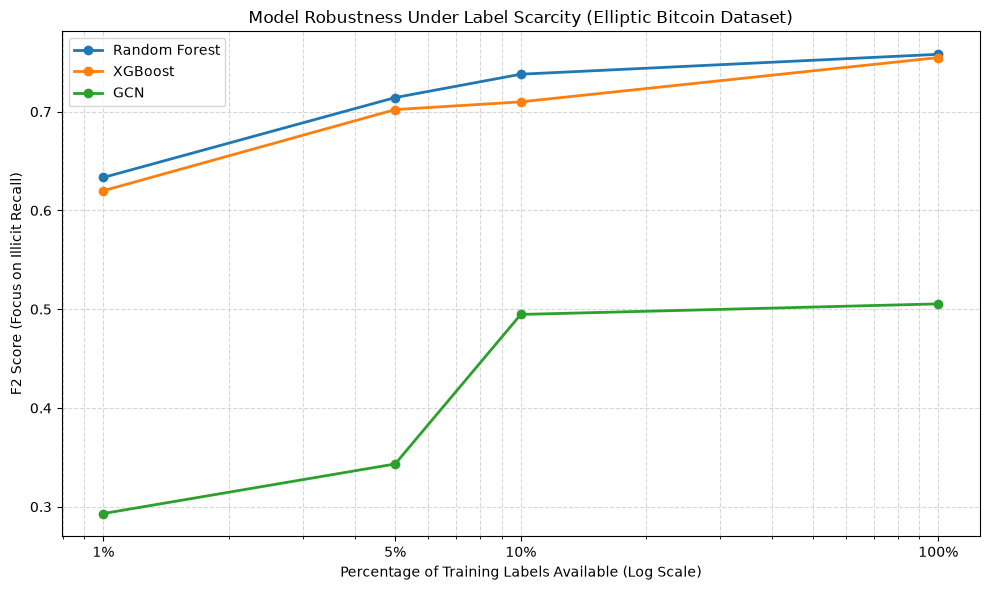

In [12]:
plt.figure(figsize=(10, 6))

for model_name, f2_scores in results.items():
    plt.plot([f * 100 for f in fractions], f2_scores, marker='o', linewidth=2, label=model_name)

plt.xscale('log')
plt.xticks([1, 5, 10, 100], labels=['1%', '5%', '10%', '100%'])
plt.xlabel('Percentage of Training Labels Available (Log Scale)')
plt.ylabel('F2 Score (Focus on Illicit Recall)')
plt.title('Model Robustness Under Label Scarcity (Elliptic Bitcoin Dataset)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('../results/label_scarcity_curve.png', dpi=300)
plt.show()